In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fixed_T_simulation import return_vals

Inflection indices: [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 25, 26, 27, 28, 29, 30, 31, 32, 34, 35, 36, 38, 39, 40, 42, 43, 44, 46, 47, 48, 49, 50, 51, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 64, 65, 66, 67, 68, 69, 71, 72, 73, 76, 78, 81, 86, 87, 89, 90, 92, 93, 94, 95, 96, 97, 99, 100, 101, 102, 103, 104, 106, 107, 108, 109, 111, 112, 114, 115, 117, 119, 122, 124, 126, 128, 130, 132, 134, 135, 136, 138, 139, 140, 142, 143, 144, 145, 146, 148, 149, 150, 152, 153, 155, 157, 159, 162, 164, 166, 167, 168, 171, 173, 175, 177, 179, 181, 182, 184, 185, 187, 189, 190, 192, 194, 196]
Inflection T values: [3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0, 6.5, 7.0, 7.5, 8.0, 8.5, 9.0, 9.5, 10.0, 10.5, 11.0, 13.0, 13.5, 14.0, 14.5, 15.0, 15.5, 16.0, 16.5, 17.5, 18.0, 18.5, 19.5, 20.0, 20.5, 21.5, 22.0, 22.5, 23.5, 24.0, 24.5, 25.0, 25.5, 26.0, 27.0, 27.5, 28.0, 28.5, 29.0, 29.5, 30.0, 30.5, 31.0, 31.5, 32.5, 33.0, 33.5, 34.0, 34.5, 35.0, 36.0, 36.5, 37.0, 38.5, 39.5, 41.0, 43.5, 44.0, 

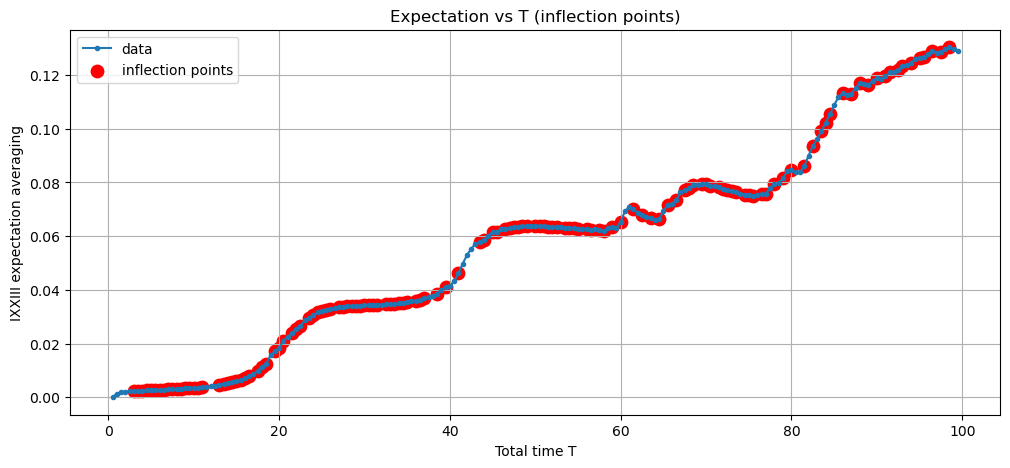

In [2]:
def find_inflection_points(T, y):
    h = T[1] - T[0]
    y2 = []# second derivative
    for i in range(1, len(y) - 1):
        second = (y[i+1] - 2*y[i] + y[i-1]) / (h*h) # second derivative
        y2.append(second)

    # points of inflection will have sign change of second derivative
    inflection_idxs = []
    for i in range(len(y2) - 1):
        if y2[i] * y2[i+1] < 0: # sign change means one of left point & right point will be neg -> the multi will be neg
            inflection_idxs.append(i + 1)  # +1 because y2 starts at index 1

    return inflection_idxs

observable = "IXXIII"

T_vals, sum_exp_vals = return_vals(observable, n=len(observable), N=20, g=1.5, num_delta_t=2, total_time=100)

inflection_idxs = find_inflection_points(T_vals, sum_exp_vals)
print("Inflection indices:", inflection_idxs)
print("Inflection T values:", [T_vals[i] for i in inflection_idxs])

plt.figure(figsize=(12, 5))
plt.plot(T_vals, sum_exp_vals, "o-", markersize=3, label="data")
plt.scatter(
    [T_vals[i] for i in inflection_idxs],
    [sum_exp_vals[i] for i in inflection_idxs],
    color="red",
    s=80,
    label="inflection points"
)
plt.grid(True)
plt.xlabel("Total time T")
plt.ylabel(f"{observable} expectation averaging")
plt.title("Expectation vs T (inflection points)")
plt.legend()
plt.show()

In [3]:
def find_flat_regions(T, y, slope_threshold=0.0003, min_points=8):
    h = T[1] - T[0]
    slope = [0] * len(y)
    for i in range(1, len(y) - 1):
        slope[i] = (y[i+1] - y[i-1]) / (2*h)

    flat = [False] * len(y)
    for i in range(1, len(y) - 1):
        if abs(slope[i]) < slope_threshold:
            flat[i] = True

    regions = []
    start = None
    for i in range(len(flat)):
        if flat[i] and start is None:
            start = i
        if (not flat[i] or i == len(flat) - 1) and start is not None:
            end = i if flat[i] else i - 1
            if end - start + 1 >= min_points:
                regions.append((start, end))
            start = None
    return regions

def region_midpoints(regions):
    mids = []
    for (a, b) in regions:
        mids.append((a + b) // 2)
    return mids

In [4]:
def plot_flat(observable):
    n = len(observable)
    T_vals, y_vals = return_vals(observable, n=n, N=20, g=1.5, num_delta_t=2, total_time=100)
    
    regions = find_flat_regions(T_vals, y_vals,
                                slope_threshold=0.00075, # old: 0.0003; possible range: 0.0001 ~ 0.001
                                min_points=10) # how long flat must last; old: 10
    
    mids = region_midpoints(regions)
    
    print("Flat regions (index ranges):", regions)
    print("Marked T values:", [T_vals[i] for i in mids])
    
    plt.figure(figsize=(12,5))
    plt.plot(T_vals, y_vals, "o-", markersize=3, label="data")
    
    plt.scatter([T_vals[i] for i in mids],
                [y_vals[i] for i in mids],
                color="red", s=120, label="flat (thermalized)")
    
    for (a, b) in regions:
        plt.axvspan(T_vals[a], T_vals[b], alpha=0.15)
    
    plt.grid(True)
    plt.xlabel("Total time T")
    plt.ylabel("Expectation averaging")
    plt.title(f"{observable}: flat regions (thermalization)")
    plt.legend()
    plt.show()

Flat regions (index ranges): [(2, 27), (51, 71), (92, 115)]
Marked T values: [7.5, 31.0, 52.0]


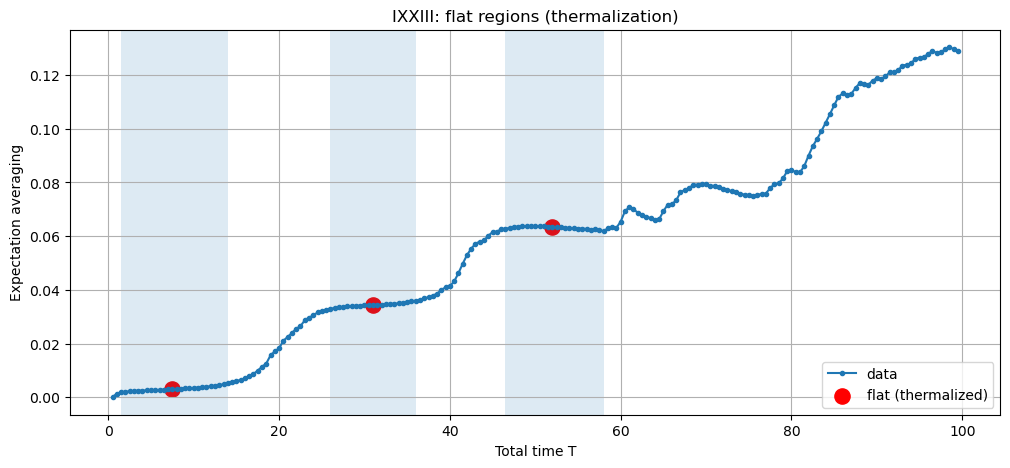

Flat regions (index ranges): [(2, 26)]
Marked T values: [7.5]


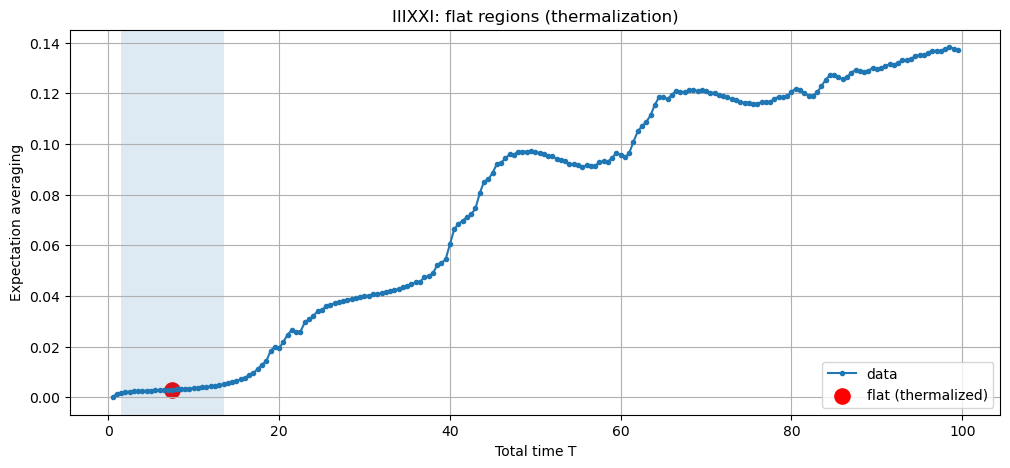

Flat regions (index ranges): [(2, 27), (52, 71), (95, 111), (139, 150)]
Marked T values: [7.5, 31.0, 52.0, 72.5]


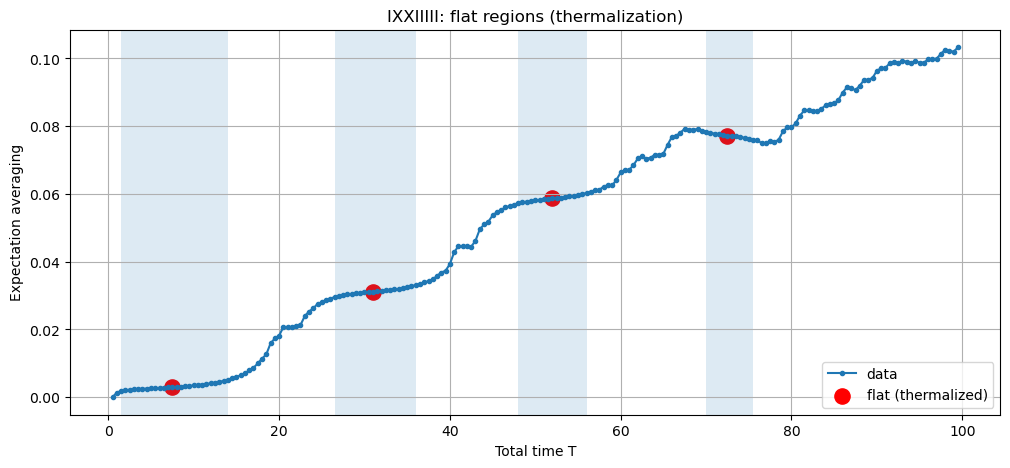

Flat regions (index ranges): [(2, 26), (53, 66)]
Marked T values: [7.5, 30.0]


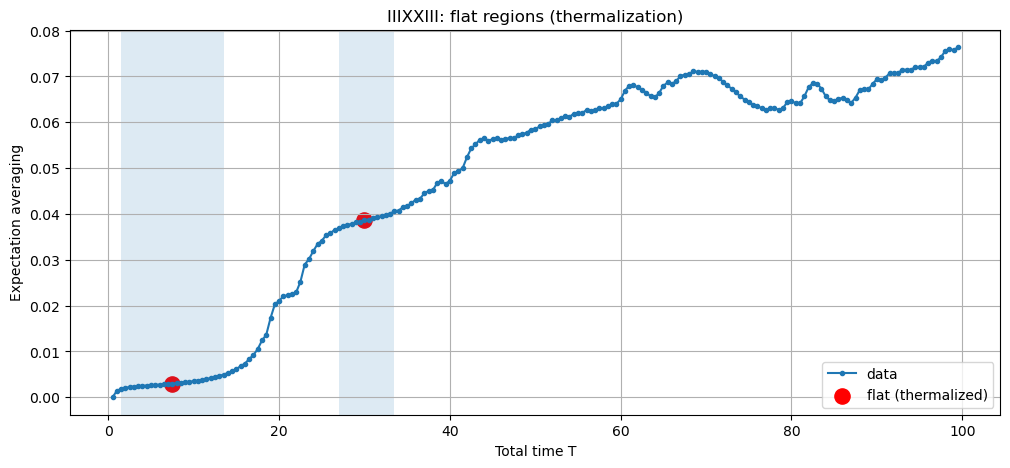

Flat regions (index ranges): [(2, 26), (55, 64), (98, 107)]
Marked T values: [7.5, 30.0, 51.5]


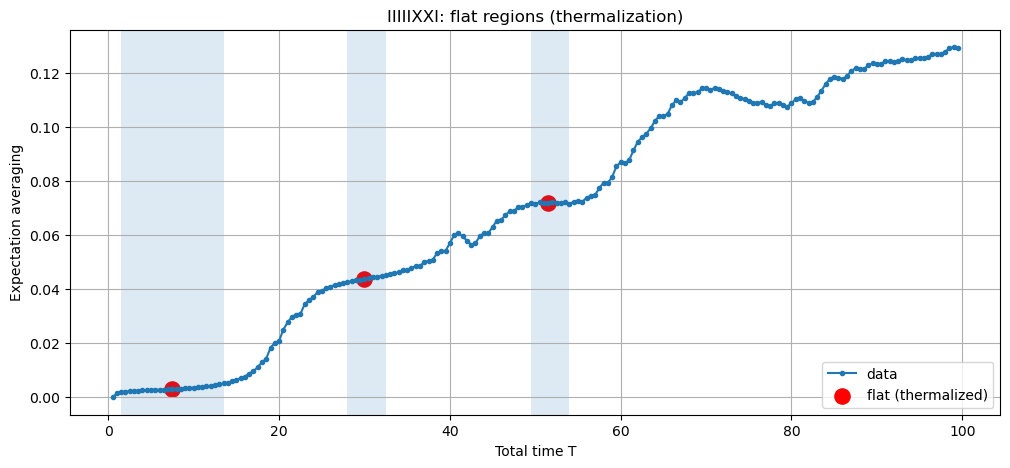

In [5]:
observables = ['IXXIII', 'IIIXXI', 'IXXIIIII', 'IIIXXIII', 'IIIIIXXI']
for observable in observables:
    plot_flat(observable)

In [183]:
def find_flat_regions_new(T, y, slope_threshold=0.001, min_points=8):
    h = T[1] - T[0]

    # compute slope
    slope = [0] * len(y)
    for i in range(1, len(y) - 1):
        slope[i] = (y[i+1] - y[i-1]) / (2*h)

    # mark flat points
    flat = [False] * len(y)
    for i in range(len(y)):
        if abs(slope[i]) < slope_threshold:
            flat[i] = True

    # group consecutive flat points
    regions = []
    start = None

    for i in range(len(flat)):
        if flat[i] and start is None:
            start = i

        if start is not None and (flat[i] == False or i == len(flat) - 1):
            if flat[i] == False:
                end = i - 1
            else:
                end = i

            if end - start + 1 >= min_points:
                regions.append((start, end))

            start = None

    return regions, slope

In [ ]:
def plot_flat_new(observable = "IXXIII"):
    n = len(observable)
    
    T_vals, y_vals = return_vals(observable, n=n, N=20, g=1.5, num_delta_t=2, total_time=100)
    
    regions, slope = find_flat_regions(T_vals, y_vals, slope_threshold=0.0008, min_points=10)
    mids = region_midpoints(regions)
    
    print("Flat regions:", regions)
    for a, b in regions:
        print("T from", T_vals[a], "to", T_vals[b])

    plt.figure(figsize=(12,5))
    plt.plot(T_vals, y_vals, "o-", markersize=3, label="data")
    
    for a, b in regions:
        plt.axvspan(T_vals[a], T_vals[b], alpha=0.2)
    
    plt.xlabel("Total time T")
    plt.ylabel("Expectation averaging")
    plt.title("Flat regions of S-shaped curve")
    plt.grid(True)
    plt.legend()
    plt.show()

In [ ]:
observables = ['IXXIII', 'IIIXXI', 'IXXIIIII', 'IIIXXIII', 'IIIIIXXI']
for observable in observables:
    plot_flat_new(observable)

ValueError: too many values to unpack (expected 2)